In [ ]:
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121

!pip install opencv-python-headless mediapipe pillow numpy pandas matplotlib seaborn scikit-learn tqdm streamlit

🔍 EKSPLORASI DATASET

Base Directory: C:\Users\User\Documents\SEMESTER 7\TUGAS AKHIR\Facial-Emotion-ASD-Copy\data\raw

📊 DISTRIBUSI DATA:

Train       :  350 Joy +  200 Sadness =  550 gambar
Test        :   42 Joy +   14 Sadness =   56 gambar
Val         :    0 Joy +    0 Sadness =    0 gambar


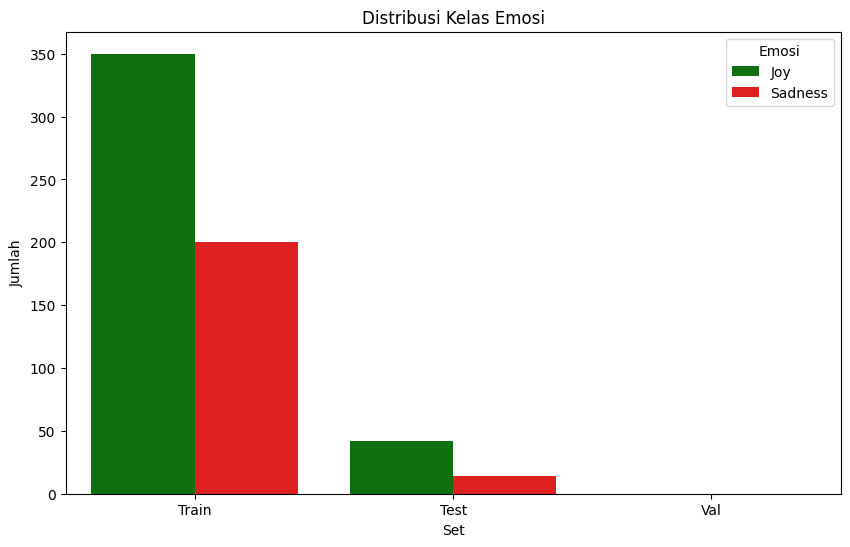


Contoh Gambar dari Train:


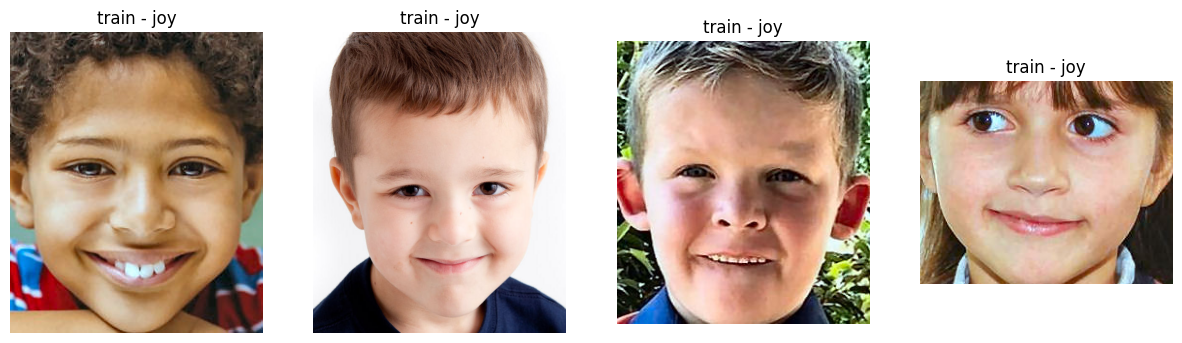

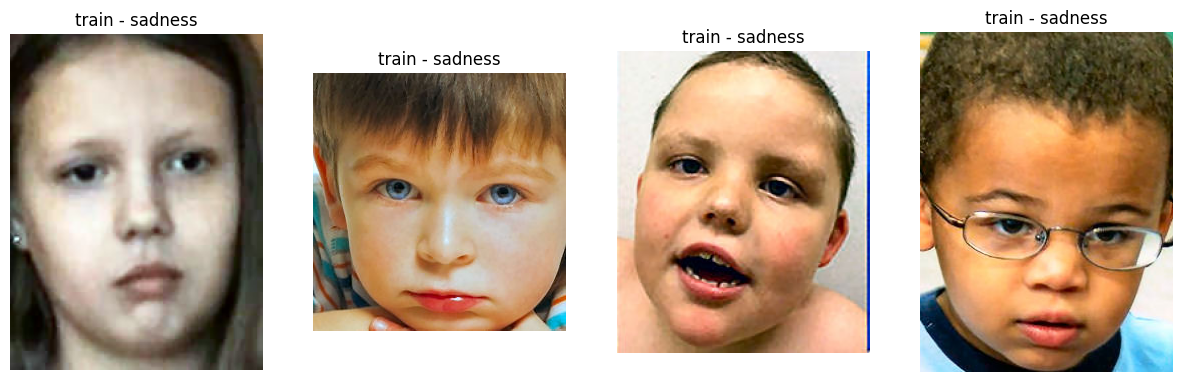


✅ Eksplorasi selesai!


In [1]:
# ==================== 01_Explorasi_Dataset.ipynb ====================

import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from PIL import Image
import random

# ==================== PATH LENGKAP KAMU ====================
base_dir = r'C:\Users\User\Documents\SEMESTER 7\TUGAS AKHIR\Facial-Emotion-ASD-Copy\data\raw'

print("🔍 EKSPLORASI DATASET\n")
print(f"Base Directory: {base_dir}\n")

# Cek apakah folder ada
folders = ['train', 'test']
if os.path.exists(os.path.join(base_dir, 'val')):
    folders.append('val')

def count_images(folder_name):
    joy_path = os.path.join(base_dir, folder_name, 'joy')
    sad_path = os.path.join(base_dir, folder_name, 'sadness')
    
    joy = len([f for f in os.listdir(joy_path) if f.lower().endswith(('.jpg','.jpeg','.png'))]) if os.path.exists(joy_path) else 0
    sad = len([f for f in os.listdir(sad_path) if f.lower().endswith(('.jpg','.jpeg','.png'))]) if os.path.exists(sad_path) else 0
    return joy, sad, joy + sad

print("📊 DISTRIBUSI DATA:\n")

for folder in folders:
    joy, sad, total = count_images(folder)
    print(f"{folder.capitalize():12}: {joy:4} Joy + {sad:4} Sadness = {total:4} gambar")

# Visualisasi
data = []
for folder in folders:
    joy, sad, total = count_images(folder)
    data.append([folder.capitalize(), joy, sad])

df = pd.DataFrame(data, columns=['Set', 'Joy', 'Sadness'])
df_melt = pd.melt(df, id_vars='Set', var_name='Emosi', value_name='Jumlah')

plt.figure(figsize=(10,6))
sns.barplot(x='Set', y='Jumlah', hue='Emosi', data=df_melt, palette=['green', 'red'])
plt.title('Distribusi Kelas Emosi')
plt.show()

# Contoh Gambar
def show_samples(folder, emotion, num=4):
    path = os.path.join(base_dir, folder, emotion)
    if not os.path.exists(path):
        print(f"Folder {folder}/{emotion} tidak ditemukan")
        return
    images = random.sample([f for f in os.listdir(path) if f.lower().endswith(('.jpg','.jpeg','.png'))], min(num, 6))
    plt.figure(figsize=(15, 5))
    for i, img_name in enumerate(images):
        img = Image.open(os.path.join(path, img_name))
        plt.subplot(1, num, i+1)
        plt.imshow(img)
        plt.title(f"{folder} - {emotion}")
        plt.axis('off')
    plt.show()

print("\nContoh Gambar dari Train:")
show_samples('train', 'joy')
show_samples('train', 'sadness')

print("\n✅ Eksplorasi selesai!")

In [6]:
# ==================== 02_Create_Validation_Set.ipynb ====================

import os
import shutil
import random

print("🚀 MEMBUAT VALIDATION SET (Sesuai Proposal)\n")

# ==================== PATH LENGKAP KAMU ====================
train_dir = r'C:\Users\User\Documents\SEMESTER 7\TUGAS AKHIR\Facial-Emotion-ASD-Copy\data\raw\train'
val_dir   = r'C:\Users\User\Documents\SEMESTER 7\TUGAS AKHIR\Facial-Emotion-ASD-Copy\data\raw\val'

# Buat folder val
os.makedirs(os.path.join(val_dir, 'joy'), exist_ok=True)
os.makedirs(os.path.join(val_dir, 'sadness'), exist_ok=True)

random.seed(42)   # agar hasil split konsisten

# Jumlah sesuai keinginan kamu
val_joy = 70
val_sad = 40

def create_val_set():
    for emotion in ['joy', 'sadness']:
        emotion_dir = os.path.join(train_dir, emotion)
        all_images = [f for f in os.listdir(emotion_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        
        if emotion == 'joy':
            num_val = val_joy
        else:
            num_val = val_sad
        
        val_images = random.sample(all_images, num_val)
        
        print(f"{emotion.upper():8} → Total gambar: {len(all_images)} | Diambil ke Validation: {num_val}")
        
        # Pindahkan gambar ke folder val
        for img_name in val_images:
            src = os.path.join(emotion_dir, img_name)
            dst = os.path.join(val_dir, emotion, img_name)
            shutil.move(src, dst)
        
        print(f"✅ {emotion} selesai\n")

# ====================== JALANKAN ======================
create_val_set()

# ====================== CEK HASIL ======================
def check_distribution(folder):
    print(f"\n=== {folder.upper()} ===")
    for emotion in ['joy', 'sadness']:
        path = os.path.join(folder, emotion)
        count = len(os.listdir(path)) if os.path.exists(path) else 0
        print(f"{emotion:8}: {count} gambar")

check_distribution(train_dir)
check_distribution(val_dir)

print("\n✅ Pembuatan Validation Set selesai!")

🚀 MEMBUAT VALIDATION SET (Sesuai Proposal)

JOY      → Total gambar: 350 | Diambil ke Validation: 70
✅ joy selesai

SADNESS  → Total gambar: 200 | Diambil ke Validation: 40
✅ sadness selesai


=== C:\USERS\USER\DOCUMENTS\SEMESTER 7\TUGAS AKHIR\FACIAL-EMOTION-ASD-COPY\DATA\RAW\TRAIN ===
joy     : 280 gambar
sadness : 160 gambar

=== C:\USERS\USER\DOCUMENTS\SEMESTER 7\TUGAS AKHIR\FACIAL-EMOTION-ASD-COPY\DATA\RAW\VAL ===
joy     : 70 gambar
sadness : 40 gambar

✅ Pembuatan Validation Set selesai!


In [7]:
# ==================== 03_Preprocessing.ipynb ====================
# Prapemrosesan Citra sesuai Bab 3 Proposal

import cv2
import mediapipe as mp
import os
from tqdm import tqdm

print("=== PRAPEMROSESAN CITRA (Face Detection + Cropping) ===\n")
print("Sesuai Bab 3: Deteksi Wajah → Cropping → (Resize dilakukan setelah segmentasi)\n")

# ==================== PATH ====================
base_dir = r'C:\Users\User\Documents\SEMESTER 7\TUGAS AKHIR\Facial-Emotion-ASD-Copy\data\raw'
processed_dir = r'C:\Users\User\Documents\SEMESTER 7\TUGAS AKHIR\Facial-Emotion-ASD-Copy\data\processed'

# Inisialisasi MediaPipe
mp_face_mesh = mp.solutions.face_mesh
face_mesh = mp_face_mesh.FaceMesh(
    static_image_mode=True,
    max_num_faces=1,
    min_detection_confidence=0.5,
    min_tracking_confidence=0.5
)

def crop_face(input_path, output_path, margin=35):
    """
    Tahap Prapemrosesan Citra:
    1. Input Dataset
    2. Face Detection
    3. Face Cropping dengan margin
    """
    img = cv2.imread(input_path)
    if img is None:
        return False
    
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    results = face_mesh.process(rgb)
    
    if not results.multi_face_landmarks:
        # Jika deteksi gagal → citra diabaikan (sesuai proposal)
        return False
    
    h, w, _ = img.shape
    landmarks = results.multi_face_landmarks[0].landmark
    
    x_coords = [int(lm.x * w) for lm in landmarks]
    y_coords = [int(lm.y * h) for lm in landmarks]
    
    # Cropping dengan margin kecil
    x_min = max(0, min(x_coords) - margin)
    x_max = min(w, max(x_coords) + margin)
    y_min = max(0, min(y_coords) - margin)
    y_max = min(h, max(y_coords) + margin)
    
    cropped = img[y_min:y_max, x_min:x_max]
    
    if cropped.size == 0:
        return False
    
    cv2.imwrite(output_path, cropped)
    return True


def process_folder(input_root, output_root):
    for emotion in ['joy', 'sadness']:
        input_dir = os.path.join(input_root, emotion)
        output_dir = os.path.join(output_root, emotion)
        os.makedirs(output_dir, exist_ok=True)
        
        print(f"\n📂 Memproses folder: {emotion}")
        images = [f for f in os.listdir(input_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        
        success = 0
        skipped = 0
        for img_name in tqdm(images):
            input_path = os.path.join(input_dir, img_name)
            output_path = os.path.join(output_dir, img_name)
            
            if crop_face(input_path, output_path):
                success += 1
            else:
                skipped += 1
                
        print(f"✅ Berhasil dicrop     : {success}")
        print(f"❌ Diabaikan (no face): {skipped}")


# ====================== JALANKAN ======================
print("🚀 Mulai Prapemrosesan Citra...\n")

process_folder(os.path.join(base_dir, 'train'), os.path.join(processed_dir, 'train'))
process_folder(os.path.join(base_dir, 'val'),   os.path.join(processed_dir, 'val'))
process_folder(os.path.join(base_dir, 'test'),   os.path.join(processed_dir, 'test'))

print("\n🎉 Prapemrosesan Citra (Cropping) selesai!")
print("Gambar hasil cropping disimpan di folder 'data/processed/'")
print("Tahap selanjutnya: Face Segmentation + Resize")

=== PRAPEMROSESAN CITRA (Face Detection + Cropping) ===

Sesuai Bab 3: Deteksi Wajah → Cropping → (Resize dilakukan setelah segmentasi)

🚀 Mulai Prapemrosesan Citra...


📂 Memproses folder: joy


100%|████████████████████████████████████████████████████████████████████████████████| 280/280 [00:08<00:00, 31.21it/s]


✅ Berhasil dicrop     : 280
❌ Diabaikan (no face): 0

📂 Memproses folder: sadness


100%|████████████████████████████████████████████████████████████████████████████████| 160/160 [00:05<00:00, 28.58it/s]


✅ Berhasil dicrop     : 160
❌ Diabaikan (no face): 0

📂 Memproses folder: joy


100%|██████████████████████████████████████████████████████████████████████████████████| 70/70 [00:02<00:00, 28.00it/s]


... (3 outputs left out)

100%|██████████████████████████████████████████████████████████████████████████████████| 42/42 [00:01<00:00, 31.47it/s]


✅ Berhasil dicrop     : 42
❌ Diabaikan (no face): 0

📂 Memproses folder: sadness


100%|██████████████████████████████████████████████████████████████████████████████████| 14/14 [00:00<00:00, 28.27it/s]

✅ Berhasil dicrop     : 14
❌ Diabaikan (no face): 0

🎉 Prapemrosesan Citra (Cropping) selesai!
Gambar hasil cropping disimpan di folder 'data/processed/'
Tahap selanjutnya: Face Segmentation + Resize


In [8]:
# ==================== 04_FaceSegmentation.ipynb ====================
# Segmentasi Wajah Berbasis Facial Landmark
# Sesuai Bab 3 Proposal:
# Input Citra Crop -> Deteksi Landmark -> Identifikasi Area Emosional
# -> Segmentasi Area Mata, Alis, Hidung, Mulut

import cv2
import mediapipe as mp
import numpy as np
import os
from tqdm import tqdm

print("=== FACE SEGMENTATION ===\n")
print("Tahapan:")
print("1. Input Citra Hasil Crop")
print("2. Deteksi Facial Landmark")
print("3. Identifikasi Area Emosional")
print("4. Segmentasi Mata, Alis, Hidung, dan Mulut\n")

# ==================== PATH ====================

input_dir = r'C:\Users\User\Documents\SEMESTER 7\TUGAS AKHIR\Facial-Emotion-ASD-Copy\data\processed'
output_dir = r'C:\Users\User\Documents\SEMESTER 7\TUGAS AKHIR\Facial-Emotion-ASD-Copy\data\segmented'

# ==================== MEDIAPIPE ====================

mp_face_mesh = mp.solutions.face_mesh

face_mesh = mp_face_mesh.FaceMesh(
    static_image_mode=True,
    max_num_faces=1,
    refine_landmarks=True,
    min_detection_confidence=0.5
)

# ==================== LANDMARK AREA ====================

# Mata kiri
LEFT_EYE = [
    33, 133, 160, 159, 158, 157, 173,
    246, 161, 163, 144, 145, 153, 154, 155
]

# Mata kanan
RIGHT_EYE = [
    362, 263, 387, 386, 385, 384, 398,
    466, 388, 390, 373, 374, 380, 381, 382
]

# Alis kiri
LEFT_EYEBROW = [
    70, 63, 105, 66, 107, 55, 65, 52
]

# Alis kanan
RIGHT_EYEBROW = [
    336, 296, 334, 293, 300, 285, 295, 282
]

# Hidung
NOSE = [
    168, 6, 197, 195, 5, 4,
    1, 19, 94, 2, 98, 327
]

# Mulut
MOUTH = [
    61, 146, 91, 181, 84, 17,
    314, 405, 321, 375, 291,
    308, 324, 318, 402, 317,
    14, 87, 178, 88, 95
]

# ==================== FUNCTION ====================

def get_points(indices, landmarks, width, height):

    points = []

    for idx in indices:
        x = int(landmarks[idx].x * width)
        y = int(landmarks[idx].y * height)

        points.append([x, y])

    return np.array(points, dtype=np.int32)


def segment_face_regions(image):

    # ===============================
    # Resize sementara untuk Face Mesh
    # ===============================

    orig_h, orig_w = image.shape[:2]

    if min(orig_h, orig_w) < 250:

        image = cv2.resize(
            image,
            None,
            fx=2,
            fy=2,
            interpolation=cv2.INTER_CUBIC
        )

    rgb = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    results = face_mesh.process(rgb)

    if not results.multi_face_landmarks:
        return None

    h, w, _ = image.shape

    landmarks = results.multi_face_landmarks[0].landmark

    mask = np.zeros(
        (h, w),
        dtype=np.uint8
    )

    regions = [
        LEFT_EYE,
        RIGHT_EYE,
        LEFT_EYEBROW,
        RIGHT_EYEBROW,
        NOSE,
        MOUTH
    ]

    for region in regions:

        pts = get_points(
            region,
            landmarks,
            w,
            h
        )

        hull = cv2.convexHull(pts)

        cv2.fillConvexPoly(
            mask,
            hull,
            255
        )

    # ===============================
    # Perbesar area emosional
    # ===============================

    kernel = np.ones(
        (25, 25),
        np.uint8
    )

    mask = cv2.dilate(
        mask,
        kernel,
        iterations=1
    )

    segmented = cv2.bitwise_and(
        image,
        image,
        mask=mask
    )

    return segmented


def process_folder(input_root, output_root):

    for emotion in ['joy', 'sadness']:

        input_path = os.path.join(
            input_root,
            emotion
        )

        output_path = os.path.join(
            output_root,
            emotion
        )

        os.makedirs(
            output_path,
            exist_ok=True
        )

        images = [
            f for f in os.listdir(input_path)
            if f.lower().endswith(
                ('.jpg', '.jpeg', '.png')
            )
        ]

        print(f"\n📂 Memproses folder: {emotion}")

        success = 0
        skipped = 0

        for img_name in tqdm(images):

            img_file = os.path.join(
                input_path,
                img_name
            )

            save_file = os.path.join(
                output_path,
                img_name
            )

            img = cv2.imread(img_file)

            if img is None:
                skipped += 1
                continue

            segmented = segment_face_regions(img)

            if segmented is None:
                skipped += 1
                continue

            cv2.imwrite(
                save_file,
                segmented
            )

            success += 1

        print(f"✅ Berhasil disegmentasi : {success}")
        print(f"❌ Gagal landmark       : {skipped}")


# ==================== RUN ====================

print("🚀 Mulai Face Segmentation...\n")

process_folder(
    os.path.join(input_dir, 'train'),
    os.path.join(output_dir, 'train')
)

process_folder(
    os.path.join(input_dir, 'val'),
    os.path.join(output_dir, 'val')
)

process_folder(
    os.path.join(input_dir, 'test'),
    os.path.join(output_dir, 'test')
)

print("\n🎉 Face Segmentation selesai!")
print("Hasil disimpan pada folder:")
print("data/segmented/")
print("\nTahap berikutnya:")
print("Resize 224x224 -> Normalisasi -> Data Augmentation -> Training CNN")

=== FACE SEGMENTATION ===

Tahapan:
1. Input Citra Hasil Crop
2. Deteksi Facial Landmark
3. Identifikasi Area Emosional
4. Segmentasi Mata, Alis, Hidung, dan Mulut

🚀 Mulai Face Segmentation...


📂 Memproses folder: joy


100%|████████████████████████████████████████████████████████████████████████████████| 280/280 [00:09<00:00, 30.14it/s]


✅ Berhasil disegmentasi : 280
❌ Gagal landmark       : 0

📂 Memproses folder: sadness


100%|████████████████████████████████████████████████████████████████████████████████| 160/160 [00:05<00:00, 29.11it/s]


✅ Berhasil disegmentasi : 160
❌ Gagal landmark       : 0

📂 Memproses folder: joy


100%|██████████████████████████████████████████████████████████████████████████████████| 70/70 [00:02<00:00, 28.14it/s]


... (3 outputs left out)

100%|██████████████████████████████████████████████████████████████████████████████████| 42/42 [00:01<00:00, 31.24it/s]


✅ Berhasil disegmentasi : 42
❌ Gagal landmark       : 0

📂 Memproses folder: sadness


100%|██████████████████████████████████████████████████████████████████████████████████| 14/14 [00:00<00:00, 25.32it/s]

✅ Berhasil disegmentasi : 14
❌ Gagal landmark       : 0

🎉 Face Segmentation selesai!
Hasil disimpan pada folder:
data/segmented/

Tahap berikutnya:
Resize 224x224 -> Normalisasi -> Data Augmentation -> Training CNN


In [9]:
import cv2
import mediapipe as mp
import os

# ==================== PATH ==================== GARIS PENGHUBUNG LANDMARK GAMBAR

sample_folder = r'C:\Users\User\Documents\SEMESTER 7\TUGAS AKHIR\Facial-Emotion-ASD-Copy\data\processed\train\joy'

image_files = [
    f for f in os.listdir(sample_folder)
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
]

image_path = os.path.join(sample_folder, image_files[0])

print("Menggunakan gambar:", image_path)

# ==================== LOAD IMAGE ====================

img = cv2.imread(image_path)

rgb = cv2.cvtColor(
    img,
    cv2.COLOR_BGR2RGB
)

# ==================== MEDIAPIPE ====================

mp_face_mesh = mp.solutions.face_mesh
mp_drawing = mp.solutions.drawing_utils
mp_styles = mp.solutions.drawing_styles

with mp_face_mesh.FaceMesh(
    static_image_mode=True,
    max_num_faces=1,
    refine_landmarks=True,
    min_detection_confidence=0.5
) as face_mesh:

    results = face_mesh.process(rgb)

    if results.multi_face_landmarks:

        annotated = img.copy()

        for face_landmarks in results.multi_face_landmarks:

            mp_drawing.draw_landmarks(
                image=annotated,
                landmark_list=face_landmarks,
                connections=mp_face_mesh.FACEMESH_TESSELATION,
                landmark_drawing_spec=None,
                connection_drawing_spec=
                mp_styles.get_default_face_mesh_tesselation_style()
            )

        save_path = "facial_landmark_visualization.jpg"

        cv2.imwrite(
            save_path,
            annotated
        )

        print(f"✅ Disimpan: {save_path}")

print("Selesai")

Menggunakan gambar: C:\Users\User\Documents\SEMESTER 7\TUGAS AKHIR\Facial-Emotion-ASD-Copy\data\processed\train\joy\0001.jpg
✅ Disimpan: facial_landmark_visualization.jpg
Selesai


In [10]:
import cv2
import mediapipe as mp
import os

# ==================== PATH GAMBAR ==================== GAMBAR TITIK FACIAL LANDMARK

image_path = r'C:\Users\User\Documents\SEMESTER 7\TUGAS AKHIR\Facial-Emotion-ASD-Copy\data\processed\train\joy\0001.jpg'

# ==================== LOAD IMAGE ====================

img = cv2.imread(image_path)

rgb = cv2.cvtColor(
    img,
    cv2.COLOR_BGR2RGB
)

# ==================== MEDIAPIPE ====================

mp_face_mesh = mp.solutions.face_mesh

face_mesh = mp_face_mesh.FaceMesh(
    static_image_mode=True,
    max_num_faces=1,
    refine_landmarks=True,
    min_detection_confidence=0.5
)

results = face_mesh.process(rgb)

if results.multi_face_landmarks:

    h, w, _ = img.shape

    landmark_img = img.copy()

    landmarks = results.multi_face_landmarks[0].landmark

    # Gambar semua titik landmark
    for lm in landmarks:

        x = int(lm.x * w)
        y = int(lm.y * h)

        cv2.circle(
            landmark_img,
            (x, y),
            1,
            (0, 0, 255),  # merah
            -1
        )

    cv2.imwrite(
        "facial_landmark_points.jpg",
        landmark_img
    )

    print("✅ Landmark berhasil disimpan")

else:
    print("❌ Wajah tidak terdeteksi")

✅ Landmark berhasil disimpan


In [11]:
# ==================== 05_Resize_Normalization.ipynb ====================
# Resize Citra ke 224x224
# Sesuai Bab 3 Proposal

import cv2
import os
from tqdm import tqdm

print("=== RESIZE CITRA ===\n")
print("Tahapan:")
print("1. Input Hasil Segmentasi")
print("2. Resize ke 224x224")
print("3. Simpan Hasil Resize\n")

# ==================== PATH ====================

input_dir = r'C:\Users\User\Documents\SEMESTER 7\TUGAS AKHIR\Facial-Emotion-ASD-Copy\data\segmented'

output_dir = r'C:\Users\User\Documents\SEMESTER 7\TUGAS AKHIR\Facial-Emotion-ASD-Copy\data\resized'

# ==================== FUNCTION ====================

def resize_image(image):

    resized = cv2.resize(
        image,
        (224, 224),
        interpolation=cv2.INTER_AREA
    )

    return resized


def process_folder(input_root, output_root):

    for emotion in ['joy', 'sadness']:

        input_path = os.path.join(
            input_root,
            emotion
        )

        output_path = os.path.join(
            output_root,
            emotion
        )

        os.makedirs(
            output_path,
            exist_ok=True
        )

        images = [
            f for f in os.listdir(input_path)
            if f.lower().endswith(
                ('.jpg', '.jpeg', '.png')
            )
        ]

        print(f"\n📂 Memproses folder: {emotion}")

        success = 0

        for img_name in tqdm(images):

            img_file = os.path.join(
                input_path,
                img_name
            )

            save_file = os.path.join(
                output_path,
                img_name
            )

            img = cv2.imread(img_file)

            if img is None:
                continue

            resized = resize_image(img)

            cv2.imwrite(
                save_file,
                resized
            )

            success += 1

        print(f"✅ Berhasil resize : {success}")

# ==================== RUN ====================

print("🚀 Mulai Resize Citra...\n")

process_folder(
    os.path.join(input_dir, 'train'),
    os.path.join(output_dir, 'train')
)

process_folder(
    os.path.join(input_dir, 'val'),
    os.path.join(output_dir, 'val')
)

process_folder(
    os.path.join(input_dir, 'test'),
    os.path.join(output_dir, 'test')
)

print("\n🎉 Resize selesai!")
print("Output tersimpan pada:")
print("data/resized/")

=== RESIZE CITRA ===

Tahapan:
1. Input Hasil Segmentasi
2. Resize ke 224x224
3. Simpan Hasil Resize

🚀 Mulai Resize Citra...


📂 Memproses folder: joy


100%|████████████████████████████████████████████████████████████████████████████████| 280/280 [00:04<00:00, 62.02it/s]


✅ Berhasil resize : 280

📂 Memproses folder: sadness


100%|████████████████████████████████████████████████████████████████████████████████| 160/160 [00:02<00:00, 59.19it/s]


✅ Berhasil resize : 160

📂 Memproses folder: joy


100%|██████████████████████████████████████████████████████████████████████████████████| 70/70 [00:01<00:00, 48.63it/s]


... (3 outputs left out)

100%|██████████████████████████████████████████████████████████████████████████████████| 42/42 [00:00<00:00, 59.99it/s]


✅ Berhasil resize : 42

📂 Memproses folder: sadness


100%|██████████████████████████████████████████████████████████████████████████████████| 14/14 [00:00<00:00, 58.53it/s]

✅ Berhasil resize : 14

🎉 Resize selesai!
Output tersimpan pada:
data/resized/


# 06_Train_MobileNetV2

In [1]:
import os
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets
from torchvision import transforms
from torchvision import models

from torch.utils.data import DataLoader

from sklearn.metrics import accuracy_score

from tqdm import tqdm

In [2]:
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device :", device)

Device : cpu


In [3]:
# path dataset

train_dir = r"C:\Users\User\Documents\SEMESTER 7\TUGAS AKHIR\Facial-Emotion-ASD-Copy\data\resized\train"

val_dir = r"C:\Users\User\Documents\SEMESTER 7\TUGAS AKHIR\Facial-Emotion-ASD-Copy\data\resized\val"

In [4]:
# Augmentasi dan Normalisasi

train_transform = transforms.Compose([

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(10),

    transforms.RandomAffine(
        degrees=0,
        translate=(0.1, 0.1)
    ),

    transforms.ColorJitter(
        brightness=0.2
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )

])

val_transform = transforms.Compose([

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )

])

In [5]:
# load dataset

train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=val_transform
)

print("Class :", train_dataset.classes)

print("Jumlah Train :", len(train_dataset))
print("Jumlah Validation :", len(val_dataset))

Class : ['joy', 'sadness']
Jumlah Train : 440
Jumlah Validation : 110


In [6]:
# data loader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Train Loader OK")
print("Validation Loader OK")

Train Loader OK
Validation Loader OK


In [7]:
# load MobileNetV2

model = models.mobilenet_v2(
    weights=models.MobileNet_V2_Weights.DEFAULT
)

print(model)

MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
  

In [8]:
# ganti output layer

num_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    num_features,
    2
)

model = model.to(device)

print(model.classifier)

Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=2, bias=True)
)


In [9]:
# Loss Function dan Optimizer

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss Function :", criterion)
print("Optimizer :", optimizer)

Loss Function : CrossEntropyLoss()
Optimizer : Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [10]:
# parameter training

EPOCHS = 30

best_val_acc = 0
best_epoch = 0

In [11]:
# =====================
# HISTORY UNTUK GRAFIK
# =====================

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

# =====================
# TRAINING DAN VALIDATION
# =====================

for epoch in range(EPOCHS):

    # =====================
    # TRAINING
    # =====================

    model.train()

    running_loss = 0

    correct_train = 0
    total_train = 0

    for images, labels in tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS}"
    ):

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, preds = torch.max(
            outputs,
            1
        )

        correct_train += (
            preds == labels
        ).sum().item()

        total_train += labels.size(0)

    # =====================
    # VALIDATION
    # =====================

    model.eval()

    running_val_loss = 0

    y_true = []
    y_pred = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            running_val_loss += loss.item()

            _, preds = torch.max(
                outputs,
                1
            )

            y_true.extend(
                labels.cpu().numpy()
            )

            y_pred.extend(
                preds.cpu().numpy()
            )

    # =====================
    # HITUNG METRIK
    # =====================

    train_loss = (
        running_loss /
        len(train_loader)
    )

    val_loss = (
        running_val_loss /
        len(val_loader)
    )

    train_acc = (
        correct_train /
        total_train
    )

    val_acc = accuracy_score(
        y_true,
        y_pred
    )

    # =====================
    # SIMPAN HISTORY
    # =====================

    train_losses.append(
        train_loss
    )

    val_losses.append(
        val_loss
    )

    train_accuracies.append(
        train_acc
    )

    val_accuracies.append(
        val_acc
    )

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Val Loss: {val_loss:.4f} "
        f"| Train Acc: {train_acc:.4f} "
        f"| Val Acc: {val_acc:.4f}"
    )

    # =====================
    # SAVE BEST MODEL
    # =====================

    if val_acc > best_val_acc:

        best_val_acc = val_acc
        best_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            "mobilenetv2_best.pth"
        )

        print(
            "✅ Model terbaik disimpan"
        )

# =====================
# HASIL TERBAIK
# =====================

print("\n========================")
print("HASIL TERBAIK")
print("========================")
print(f"Best Epoch          : {best_epoch}")
print(f"Best Validation Acc : {best_val_acc:.4f}")

Epoch 1/30: 100%|██████████████████████████████████████████████████████████████████████| 14/14 [01:05<00:00,  4.71s/it]


Epoch [1/30] | Train Loss: 0.5022 | Val Loss: 0.6032 | Train Acc: 0.7364 | Val Acc: 0.8091
✅ Model terbaik disimpan


Epoch 2/30: 100%|██████████████████████████████████████████████████████████████████████| 14/14 [00:57<00:00,  4.09s/it]


Epoch [2/30] | Train Loss: 0.3416 | Val Loss: 0.3344 | Train Acc: 0.8750 | Val Acc: 0.9182
✅ Model terbaik disimpan


Epoch 3/30: 100%|██████████████████████████████████████████████████████████████████████| 14/14 [00:58<00:00,  4.18s/it]


Epoch [3/30] | Train Loss: 0.2470 | Val Loss: 0.2904 | Train Acc: 0.8955 | Val Acc: 0.9182


... (50 outputs left out)

Epoch 29/30: 100%|█████████████████████████████████████████████████████████████████████| 14/14 [01:13<00:00,  5.27s/it]


Epoch [29/30] | Train Loss: 0.0753 | Val Loss: 0.7506 | Train Acc: 0.9705 | Val Acc: 0.8364


Epoch 30/30: 100%|█████████████████████████████████████████████████████████████████████| 14/14 [01:14<00:00,  5.29s/it]


Epoch [30/30] | Train Loss: 0.0734 | Val Loss: 0.2762 | Train Acc: 0.9795 | Val Acc: 0.8727

HASIL TERBAIK
Best Epoch          : 19
Best Validation Acc : 0.9364


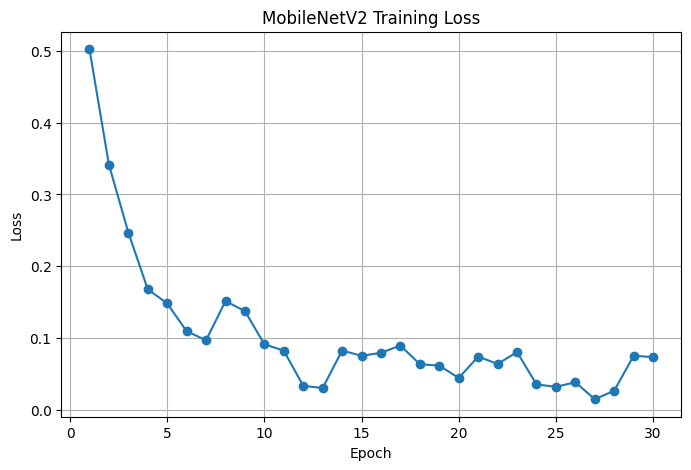

In [13]:
# =====================
# GRAFIK LOSS
# =====================

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    range(1, len(train_losses)+1),
    train_losses,
    marker='o'
)

plt.title("MobileNetV2 Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)

plt.savefig(
    "mobilenetv2_loss.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

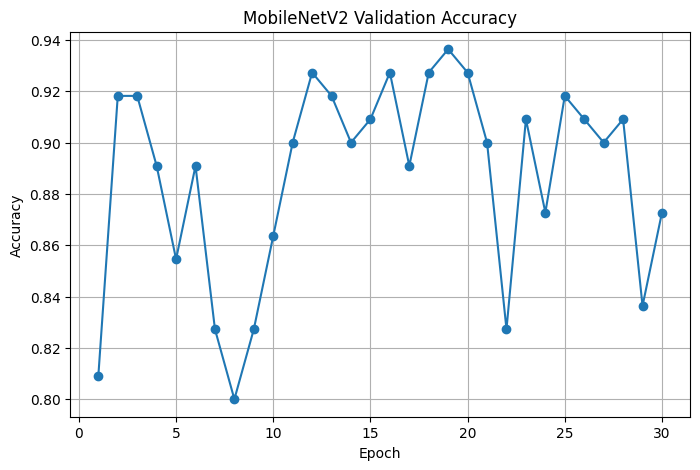

In [14]:
# =====================
# GRAFIK ACCURACY
# =====================

plt.figure(figsize=(8,5))

plt.plot(
    range(1, len(val_accuracies)+1),
    val_accuracies,
    marker='o'
)

plt.title("MobileNetV2 Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)

plt.savefig(
    "mobilenetv2_accuracy.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

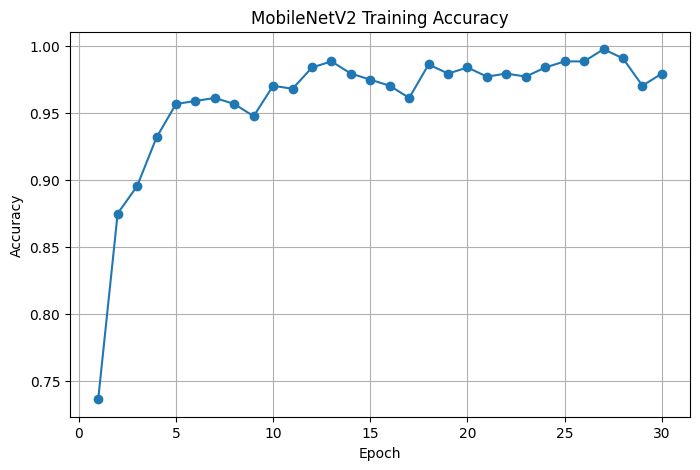

In [20]:
# =====================
# GRAFIK TRAINING ACCURACY
# =====================

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    range(1, len(train_accuracies)+1),
    train_accuracies,
    marker='o'
)

plt.title("MobileNetV2 Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)

plt.savefig(
    "mobilenetv2_train_accuracy.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

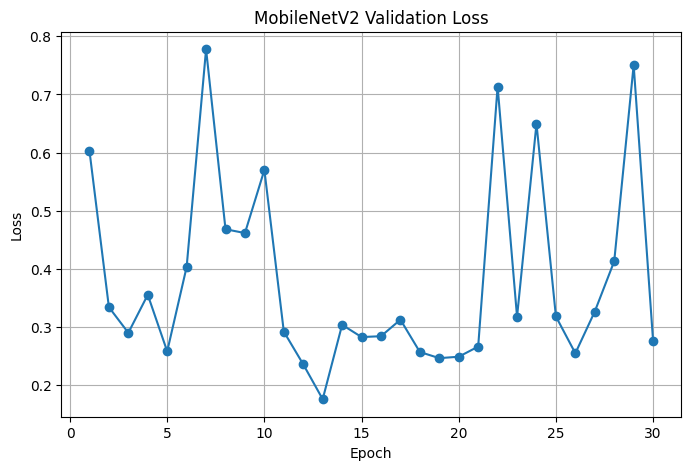

In [17]:
# =====================
# GRAFIK VALIDATION LOSS
# =====================

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    range(1, len(val_losses)+1),
    val_losses,
    marker='o'
)

plt.title("MobileNetV2 Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)

plt.savefig(
    "mobilenetv2_val_loss.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

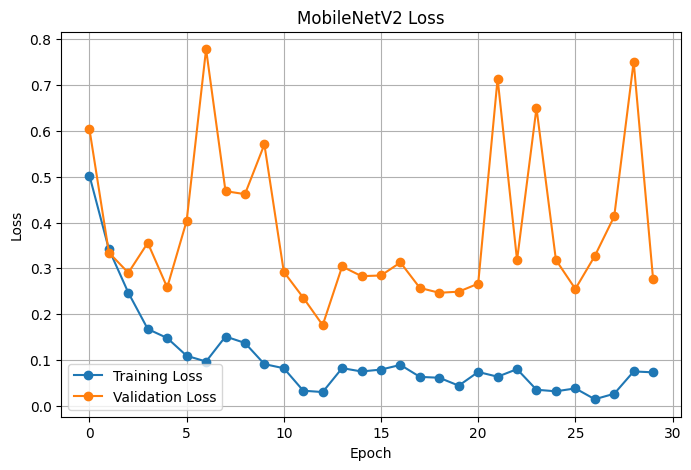

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    train_losses,
    marker='o',
    label='Training Loss'
)

plt.plot(
    val_losses,
    marker='o',
    label='Validation Loss'
)

plt.title("MobileNetV2 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

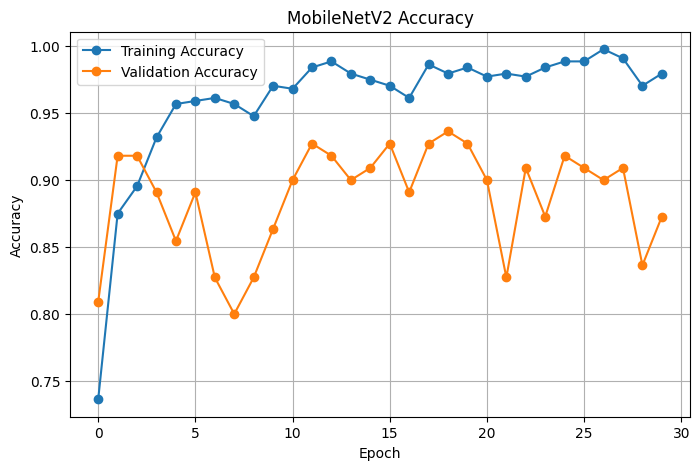

In [16]:
plt.figure(figsize=(8,5))

plt.plot(
    train_accuracies,
    marker='o',
    label='Training Accuracy'
)

plt.plot(
    val_accuracies,
    marker='o',
    label='Validation Accuracy'
)

plt.title("MobileNetV2 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

In [12]:
# hasil training

print("\n===== TRAINING SELESAI =====")

print(
    f"Best Validation Accuracy : "
    f"{best_val_acc:.4f}"
)

print(
    f"Best Epoch : "
    f"{best_epoch}"
)

print(
    "Model tersimpan sebagai : "
    "mobilenetv2_best.pth"
)


===== TRAINING SELESAI =====
Best Validation Accuracy : 0.9364
Best Epoch : 19
Model tersimpan sebagai : mobilenetv2_best.pth


# 07_testing MobileNetV2

In [21]:
import torch
import torch.nn as nn

from torchvision import datasets
from torchvision import transforms
from torchvision import models

from torch.utils.data import DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import numpy as np

In [22]:
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device :", device)

Device : cpu


In [23]:
# path dataset

test_dir = r"C:\Users\User\Documents\SEMESTER 7\TUGAS AKHIR\Facial-Emotion-ASD-Copy\data\resized\test"

In [24]:
# transform test

test_transform = transforms.Compose([

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )

])

In [25]:
# Dataset dan DataLoader

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print("Classes :", test_dataset.classes)

Classes : ['joy', 'sadness']


In [26]:
# Load Arsitektur MobileNetV2

model = models.mobilenet_v2(
    weights=None
)

num_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    num_features,
    2
)

In [27]:
# load model terbaik

model.load_state_dict(
    torch.load(
        "mobilenetv2_best.pth",
        map_location=device
    )
)

model = model.to(device)

model.eval()

print("Model berhasil dimuat")

Model berhasil dimuat


In [28]:
# testing

y_true = []
y_pred = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        _, preds = torch.max(
            outputs,
            1
        )

        y_true.extend(
            labels.numpy()
        )

        y_pred.extend(
            preds.cpu().numpy()
        )

In [29]:
# Hitung Metrik

accuracy = accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    average='weighted'
)

recall = recall_score(
    y_true,
    y_pred,
    average='weighted'
)

f1 = f1_score(
    y_true,
    y_pred,
    average='weighted'
)

print("\n===== HASIL TESTING =====")

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")


===== HASIL TESTING =====
Accuracy  : 0.9286
Precision : 0.9280
Recall    : 0.9286
F1 Score  : 0.9267


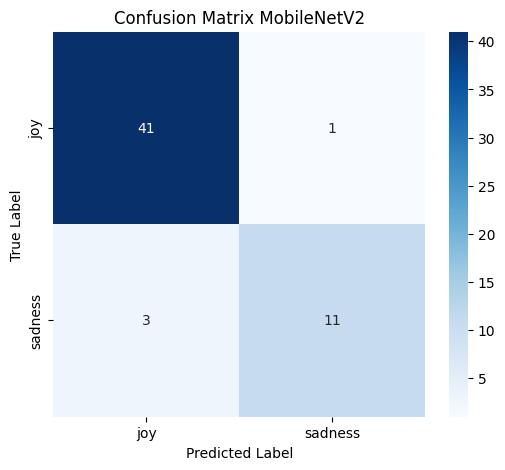

In [30]:
# confusion matrix

import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=test_dataset.classes,
    yticklabels=test_dataset.classes
)

plt.title(
    "Confusion Matrix MobileNetV2"
)

plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.show()

In [31]:
# classification report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=test_dataset.classes
    )
)

              precision    recall  f1-score   support

         joy       0.93      0.98      0.95        42
     sadness       0.92      0.79      0.85        14

    accuracy                           0.93        56
   macro avg       0.92      0.88      0.90        56
weighted avg       0.93      0.93      0.93        56



# 08_TrainResNet18

In [32]:
import os
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets
from torchvision import transforms
from torchvision import models

from torch.utils.data import DataLoader

from sklearn.metrics import accuracy_score

from tqdm import tqdm

In [33]:
#cek device
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device :", device)

Device : cpu


In [34]:
#path dataset
train_dir = r"C:\Users\User\Documents\SEMESTER 7\TUGAS AKHIR\Facial-Emotion-ASD-Copy\data\resized\train"

val_dir = r"C:\Users\User\Documents\SEMESTER 7\TUGAS AKHIR\Facial-Emotion-ASD-Copy\data\resized\val"

In [35]:
# Augmentasi dan Normalisasi
train_transform = transforms.Compose([

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(10),

    transforms.RandomAffine(
        degrees=0,
        translate=(0.1, 0.1)
    ),

    transforms.ColorJitter(
        brightness=0.2
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


In [36]:
# load dataset

train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=val_transform
)

print("Class :", train_dataset.classes)
print("Jumlah Train :", len(train_dataset))
print("Jumlah Validation :", len(val_dataset))

Class : ['joy', 'sadness']
Jumlah Train : 440
Jumlah Validation : 110


In [37]:
# data loader
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Train Loader OK")
print("Validation Loader OK")

Train Loader OK
Validation Loader OK


In [38]:
# load ResNet18
model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [39]:
# ganti layer output
num_features = model.fc.in_features

model.fc = nn.Linear(
    num_features,
    2
)

model = model.to(device)
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [40]:
# Loss Function dan optimizer

criterion = nn.CrossEntropyLoss()

# optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss Function :", criterion)
print("Optimizer :", optimizer)

Loss Function : CrossEntropyLoss()
Optimizer : Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [41]:
# Parameter training 

EPOCHS = 30

best_val_acc = 0
best_epoch = 0

In [42]:
# =====================
# HISTORY UNTUK GRAFIK
# =====================

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

# =====================
# TRAINING DAN VALIDATION
# =====================

for epoch in range(EPOCHS):

    # =====================
    # TRAINING
    # =====================

    model.train()

    running_loss = 0

    correct_train = 0
    total_train = 0

    for images, labels in tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS}"
    ):

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, preds = torch.max(
            outputs,
            1
        )

        correct_train += (
            preds == labels
        ).sum().item()

        total_train += labels.size(0)

    # =====================
    # VALIDATION
    # =====================

    model.eval()

    running_val_loss = 0

    y_true = []
    y_pred = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            running_val_loss += loss.item()

            _, preds = torch.max(
                outputs,
                1
            )

            y_true.extend(
                labels.cpu().numpy()
            )

            y_pred.extend(
                preds.cpu().numpy()
            )

    # =====================
    # HITUNG METRIK
    # =====================

    train_loss = (
        running_loss /
        len(train_loader)
    )

    val_loss = (
        running_val_loss /
        len(val_loader)
    )

    train_acc = (
        correct_train /
        total_train
    )

    val_acc = accuracy_score(
        y_true,
        y_pred
    )

    # =====================
    # SIMPAN HISTORY
    # =====================

    train_losses.append(
        train_loss
    )

    val_losses.append(
        val_loss
    )

    train_accuracies.append(
        train_acc
    )

    val_accuracies.append(
        val_acc
    )

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Val Loss: {val_loss:.4f} "
        f"| Train Acc: {train_acc:.4f} "
        f"| Val Acc: {val_acc:.4f}"
    )

    # =====================
    # SAVE BEST MODEL
    # =====================

    if val_acc > best_val_acc:

        best_val_acc = val_acc
        best_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            "resnet18_best.pth"
        )

        print(
            "✅ Model terbaik disimpan"
        )

# =====================
# HASIL TERBAIK
# =====================

print("\n========================")
print("HASIL TERBAIK RESNET18")
print("========================")
print(f"Best Epoch          : {best_epoch}")
print(f"Best Validation Acc : {best_val_acc:.4f}")

Epoch 1/30: 100%|██████████████████████████████████████████████████████████████████████| 14/14 [02:00<00:00,  8.62s/it]


Epoch [1/30] | Train Loss: 0.6300 | Val Loss: 4.1830 | Train Acc: 0.7295 | Val Acc: 0.6636
✅ Model terbaik disimpan


Epoch 2/30: 100%|██████████████████████████████████████████████████████████████████████| 14/14 [01:48<00:00,  7.76s/it]


Epoch [2/30] | Train Loss: 0.3702 | Val Loss: 0.2690 | Train Acc: 0.8409 | Val Acc: 0.8909
✅ Model terbaik disimpan


Epoch 3/30: 100%|██████████████████████████████████████████████████████████████████████| 14/14 [02:04<00:00,  8.90s/it]


Epoch [3/30] | Train Loss: 0.3161 | Val Loss: 0.3583 | Train Acc: 0.8682 | Val Acc: 0.8727


... (50 outputs left out)

Epoch 29/30: 100%|█████████████████████████████████████████████████████████████████████| 14/14 [02:33<00:00, 10.94s/it]


Epoch [29/30] | Train Loss: 0.0592 | Val Loss: 0.5300 | Train Acc: 0.9773 | Val Acc: 0.9000


Epoch 30/30: 100%|█████████████████████████████████████████████████████████████████████| 14/14 [02:47<00:00, 11.99s/it]


Epoch [30/30] | Train Loss: 0.0651 | Val Loss: 0.3898 | Train Acc: 0.9773 | Val Acc: 0.8727

HASIL TERBAIK RESNET18
Best Epoch          : 15
Best Validation Acc : 0.9273


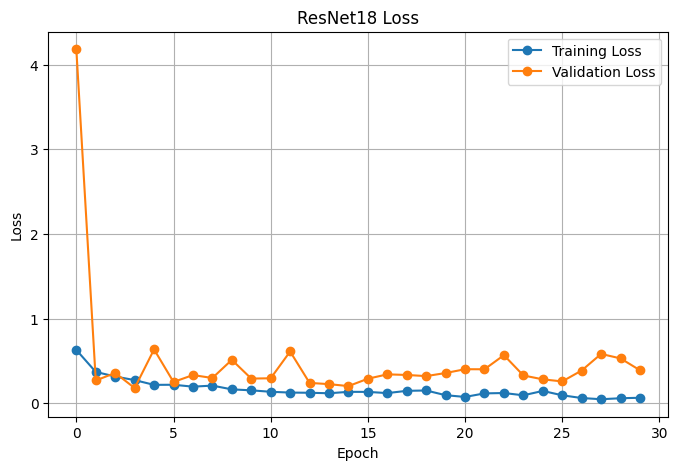

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    train_losses,
    marker='o',
    label='Training Loss'
)

plt.plot(
    val_losses,
    marker='o',
    label='Validation Loss'
)

plt.title("ResNet18 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.savefig(
    "resnet18_loss.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

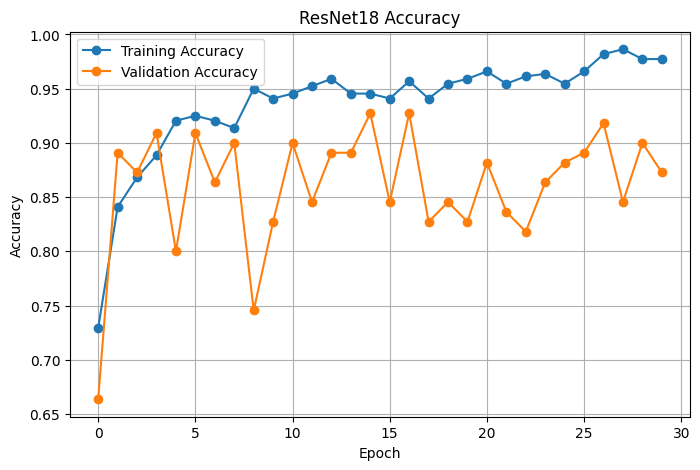

In [44]:
plt.figure(figsize=(8,5))

plt.plot(
    train_accuracies,
    marker='o',
    label='Training Accuracy'
)

plt.plot(
    val_accuracies,
    marker='o',
    label='Validation Accuracy'
)

plt.title("ResNet18 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.savefig(
    "resnet18_accuracy.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

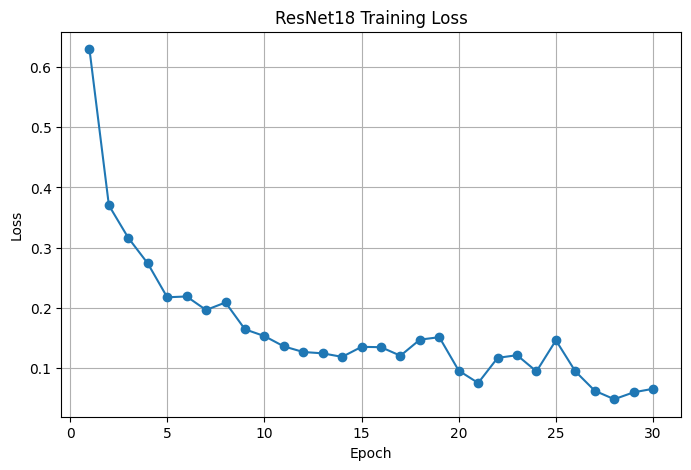

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    range(1, len(train_losses)+1),
    train_losses,
    marker='o'
)

plt.title("ResNet18 Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)

plt.savefig(
    "resnet18_loss.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

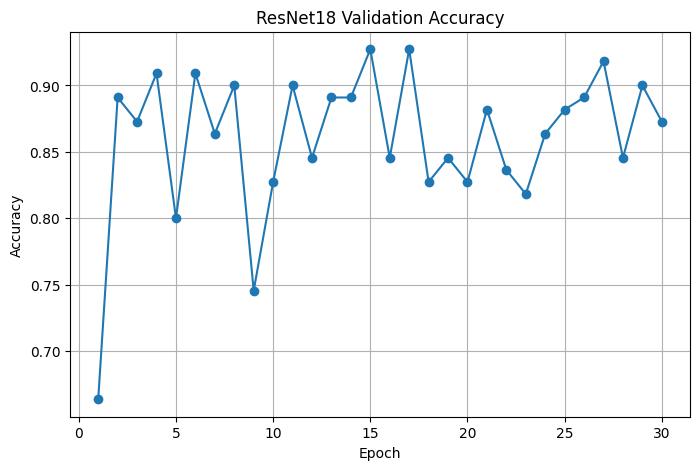

In [46]:
plt.figure(figsize=(8,5))

plt.plot(
    range(1, len(val_accuracies)+1),
    val_accuracies,
    marker='o'
)

plt.title("ResNet18 Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)

plt.savefig(
    "resnet18_accuracy.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

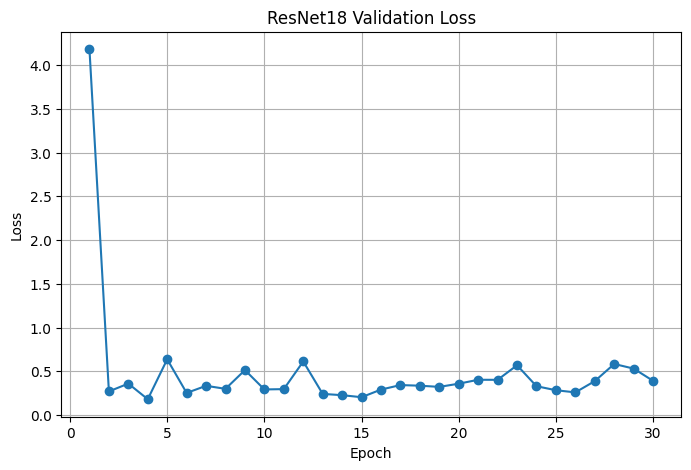

In [47]:
plt.figure(figsize=(8,5))

plt.plot(
    range(1, len(val_losses)+1),
    val_losses,
    marker='o'
)

plt.title("ResNet18 Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)

plt.show()

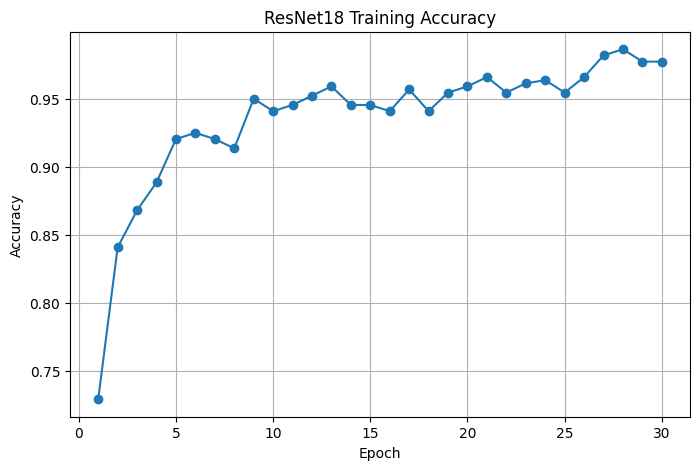

In [48]:
plt.figure(figsize=(8,5))

plt.plot(
    range(1, len(train_accuracies)+1),
    train_accuracies,
    marker='o'
)

plt.title("ResNet18 Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)

plt.show()

In [49]:
# Hasil training

print("\n===== TRAINING SELESAI =====")

print(
    f"Best Validation Accuracy : "
    f"{best_val_acc:.4f}"
)

print(
    f"Best Epoch : "
    f"{best_epoch}"
)

print(
    "Model tersimpan sebagai : "
    "resnet18_best.pth"
)


===== TRAINING SELESAI =====
Best Validation Accuracy : 0.9273
Best Epoch : 15
Model tersimpan sebagai : resnet18_best.pth


# 09_Test_ResNet18

In [50]:
import torch
import torch.nn as nn

from torchvision import datasets
from torchvision import transforms
from torchvision import models

from torch.utils.data import DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

In [51]:
#device

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device :", device)

Device : cpu


In [52]:
# path dataset
test_dir = r"C:\Users\User\Documents\SEMESTER 7\TUGAS AKHIR\Facial-Emotion-ASD-Copy\data\resized\test"

In [53]:
# transform test

test_transform = transforms.Compose([

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )

])

In [54]:
# dataset dan dataLoader

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print(test_dataset.classes)

['joy', 'sadness']


In [55]:
# Load asitektur ResNet18

model = models.resnet18(
    weights=None
)

num_features = model.fc.in_features

model.fc = nn.Linear(
    num_features,
    2
)

In [56]:
# Load model terbaik

model.load_state_dict(
    torch.load(
        "resnet18_best.pth",
        map_location=device
    )
)

model = model.to(device)

model.eval()

print("Model berhasil dimuat")

Model berhasil dimuat


In [57]:
# testing

y_true = []
y_pred = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        _, preds = torch.max(
            outputs,
            1
        )

        y_true.extend(
            labels.numpy()
        )

        y_pred.extend(
            preds.cpu().numpy()
        )

In [58]:
# hitung metrik

accuracy = accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    average='weighted'
)

recall = recall_score(
    y_true,
    y_pred,
    average='weighted'
)

f1 = f1_score(
    y_true,
    y_pred,
    average='weighted'
)

print("\n===== HASIL TESTING =====")

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")


===== HASIL TESTING =====
Accuracy  : 0.9464
Precision : 0.9500
Recall    : 0.9464
F1 Score  : 0.9441


In [59]:
# classification report lengkap

print(
    classification_report(
        y_true,
        y_pred,
        target_names=test_dataset.classes
    )
)

              precision    recall  f1-score   support

         joy       0.93      1.00      0.97        42
     sadness       1.00      0.79      0.88        14

    accuracy                           0.95        56
   macro avg       0.97      0.89      0.92        56
weighted avg       0.95      0.95      0.94        56



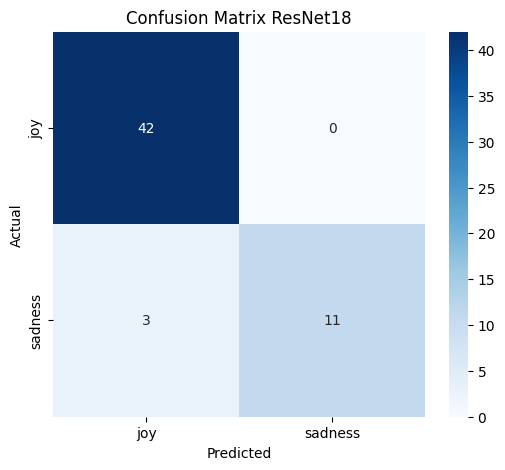

In [61]:
# confusion matrix berwarna

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=test_dataset.classes,
    yticklabels=test_dataset.classes
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix ResNet18")

plt.show()

# 10_compare_models

In [64]:
import pandas as pd
import matplotlib.pyplot as plt

In [65]:
# input hasil evaluasi

mobilenet = {
    "Model": "MobileNetV2",
    "Accuracy": 0.9286,
    "Precision": 0.9280,
    "Recall": 0.9286,
    "F1-Score": 0.9267
}

resnet = {
    "Model": "ResNet18",
    "Accuracy": 0.9464,
    "Precision": 0.9500,
    "Recall": 0.9464,
    "F1-Score": 0.9441
}


In [66]:
#buat tabel perbandingan

df = pd.DataFrame([
    mobilenet,
    resnet
])

df

,Model,Accuracy,Precision,Recall,F1-Score
0,MobileNetV2,0.9286,0.928,0.9286,0.9267
1,ResNet18,0.9464,0.950,0.9464,0.9441


In [67]:
best_model = df.loc[
    df["Accuracy"].idxmax()
]

print("Model Terbaik:")
print(best_model["Model"])

Model Terbaik:
ResNet18


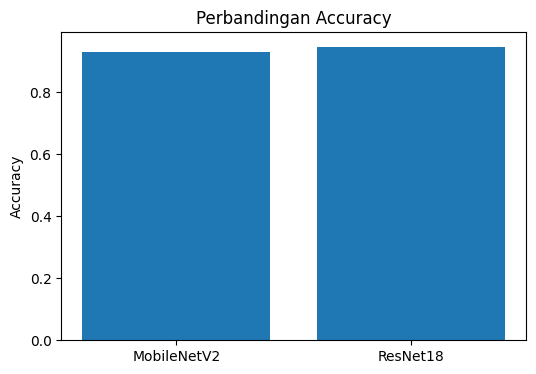

In [68]:
plt.figure(figsize=(6,4))

plt.bar(
    df["Model"],
    df["Accuracy"]
)

plt.title("Perbandingan Accuracy")
plt.ylabel("Accuracy")

plt.show()

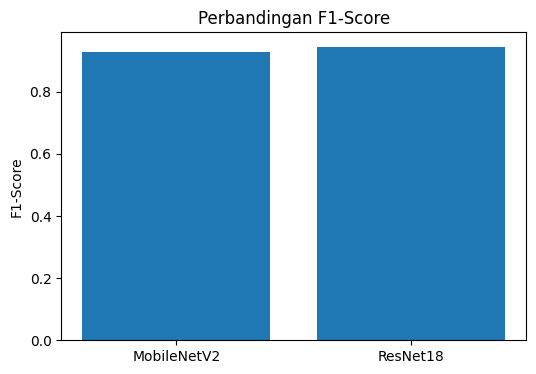

In [69]:
plt.figure(figsize=(6,4))

plt.bar(
    df["Model"],
    df["F1-Score"]
)

plt.title("Perbandingan F1-Score")
plt.ylabel("F1-Score")

plt.show()

In [70]:
print("\n===== KESIMPULAN =====")

if resnet["Accuracy"] > mobilenet["Accuracy"]:

    print(
        "ResNet18 memiliki performa lebih baik "
        "dibanding MobileNetV2."
    )

elif mobilenet["Accuracy"] > resnet["Accuracy"]:

    print(
        "MobileNetV2 memiliki performa lebih baik "
        "dibanding ResNet18."
    )

else:

    print(
        "Kedua model memiliki performa yang sama."
    )


===== KESIMPULAN =====
ResNet18 memiliki performa lebih baik dibanding MobileNetV2.


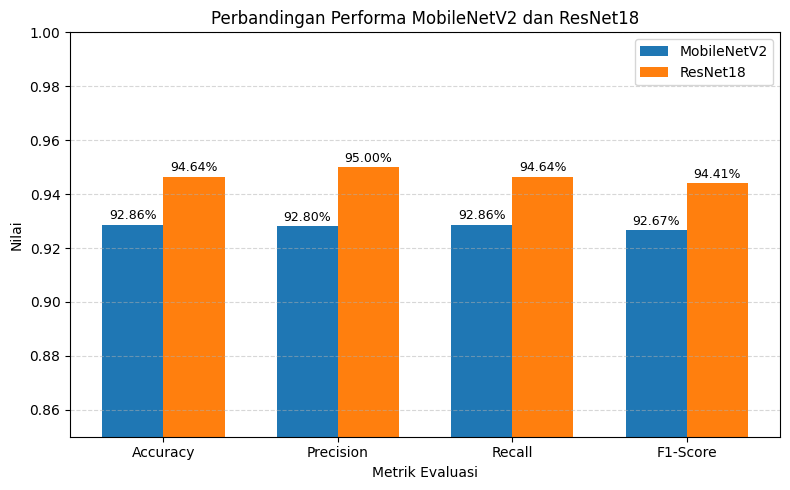

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Data

mobilenet = {
    "Accuracy": 0.9286,
    "Precision": 0.9280,
    "Recall": 0.9286,
    "F1-Score": 0.9267
}

resnet = {
    "Accuracy": 0.9464,
    "Precision": 0.9500,
    "Recall": 0.9464,
    "F1-Score": 0.9441
}

# Metrik

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

mobilenet_values = [
    mobilenet[m]
    for m in metrics
]

resnet_values = [
    resnet[m]
    for m in metrics
]

# Posisi batang

x = np.arange(
    len(metrics)
)

width = 0.35

# Plot

plt.figure(
    figsize=(8,5)
)

plt.bar(
    x - width/2,
    mobilenet_values,
    width,
    label="MobileNetV2"
)

plt.bar(
    x + width/2,
    resnet_values,
    width,
    label="ResNet18"
)

# Label nilai

for i, v in enumerate(mobilenet_values):

    plt.text(
        i - width/2,
        v + 0.002,
        f"{v*100:.2f}%",
        ha="center",
        fontsize=9
    )

for i, v in enumerate(resnet_values):

    plt.text(
        i + width/2,
        v + 0.002,
        f"{v*100:.2f}%",
        ha="center",
        fontsize=9
    )

plt.xticks(
    x,
    metrics
)

plt.ylabel(
    "Nilai"
)

plt.xlabel(
    "Metrik Evaluasi"
)

plt.title(
    "Perbandingan Performa MobileNetV2 dan ResNet18"
)

plt.ylim(
    0.85,
    1.00
)

plt.legend()

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.5
)

plt.tight_layout()

plt.savefig(
    "perbandingan_model.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()